# NN_L7_model_comparison

**Lecture 7 of Neural Networks and Deep Learning (NN), attention and transformers. Macro-F1 on 2,388 test tweets for TF-IDF + logistic regression, an embedding bag, a small transformer with and without positions, and FinBERT zero-shot, frozen + logistic and fine-tuned (mean and sd over seeds).**

Neural Networks and Deep Learning (NN), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L7/NN_L7_model_comparison/NN_L7_model_comparison.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Mean over the runs of each model (3 seeds for the trained networks).

macro-F1, TF-IDF (%) = 75.5   [models.tfidf.macro_f1]
macro-F1, FinBERT fine-tuned (%) = 84.8   [models.finbert_ft.macro_f1]
macro-F1, small transformer (%) = 68.8   [models.tiny.macro_f1]


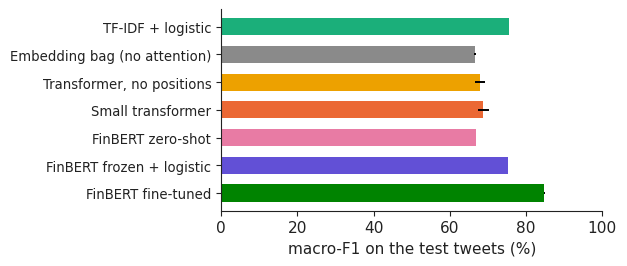

In [3]:
m = pd.read_csv(REPO + 'lectures/L7/results/' + 'model_metrics.csv')
g = m.groupby('model').macro_f1.agg(['mean', 'std']).fillna(0)
show('models.tfidf.macro_f1', 'macro-F1, TF-IDF (%)', round(100 * float(g.loc['tfidf', 'mean']), 1))
show('models.finbert_ft.macro_f1', 'macro-F1, FinBERT fine-tuned (%)', round(100 * float(g.loc['finbert_ft', 'mean']), 1))
show('models.tiny.macro_f1', 'macro-F1, small transformer (%)', round(100 * float(g.loc['tiny', 'mean']), 1))
order = ['tfidf', 'embbag', 'tiny_nopos', 'tiny', 'finbert_zs', 'finbert_probe', 'finbert_ft']
names = ['TF-IDF + logistic', 'Embedding bag (no attention)', 'Transformer, no positions', 'Small transformer', 'FinBERT zero-shot', 'FinBERT frozen + logistic', 'FinBERT fine-tuned']
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.barh(range(7), [100 * g.loc[o, 'mean'] for o in order], xerr=[100 * g.loc[o, 'std'] for o in order], color=[PAL['benchmark'], '#8a8a8a', PAL['alt'], PAL['model'], '#e87ba4', '#6250d6', '#008300'], height=0.62)
ax.set_yticks(range(7)); ax.set_yticklabels(names, fontsize=9.5); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('macro-F1 on the test tweets (%)')
fig.tight_layout()
fig.savefig('model_comparison.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()